# CardioIA — Fase 3, Ir Além 2: IA em séries temporais de batimentos

**Integrantes:** Victor Copque dos Reis (RM566821) · Victor Hugo Ferreira Rolim (RM568006)

**Pergunta:** cada batimento do coração é **normal** ou **anormal** (arritmia)?

Comparamos dois modelos com **exatamente a mesma entrada**:

| | Modelo | Ideia |
|---|---|---|
| A | **Regressão logística** | classificador tradicional: uma soma ponderada das entradas passa por uma sigmoide |
| B | **Rede neuromórfica LIF** | 300 neurônios *Leaky Integrate-and-Fire* que recebem o sinal amostra por amostra e se comunicam por *spikes*, como neurônios biológicos |

Roteiro:

1. Dados reais de ECG (MIT-BIH, PhysioNet) e a série temporal dos intervalos entre batimentos.
2. Pré-processamento: janela de cada batimento + atributos de ritmo (RR).
3. Modelo A: regressão logística.
4. Modelo B: o neurônio LIF, a rede e a leitura dos spikes.
5. Comparação: desempenho, custo, robustez a ruído.
6. Conclusões: vantagens e limitações de cada abordagem.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (balanced_accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

SEMENTE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COR_A, COR_B = "#1f77b4", "#b42318"   # regressão logística, LIF

## 1. Os dados: MIT-BIH Arrhythmia Database

48 gravações de ECG de 30 minutos, 360 amostras por segundo, em que **cada
batimento foi anotado por dois cardiologistas** (PhysioNet, Moody & Mark, 2001).
Baixamos direto do PhysioNet com a biblioteca `wfdb` (≈ 80 MB, só na primeira
execução; a pasta `dados/` fica fora do git).

Agrupamos as anotações nas classes da norma **AAMI EC57**, padrão da área:

| Classe | Símbolos | Nesta análise |
|---|---|---|
| N — normal (inclui bloqueios de ramo) | `N L R e j` | **normal (0)** |
| S — ectópico supraventricular | `A a J S` | **anormal (1)** |
| V — ectópico ventricular | `V E` | **anormal (1)** |
| F — fusão | `F` | **anormal (1)** |

**Separação por paciente (inter-patient).** O erro mais comum com o MIT-BIH é
sortear batimentos para treino e teste: batimentos do mesmo paciente caem nos
dois lados e o modelo "decora" a pessoa, inflando a nota. Usamos a divisão de
**de Chazal et al. (2004)**: 22 gravações para treino (DS1) e 22 **de outros
pacientes** para teste (DS2). As 4 gravações com marca-passo ficam de fora,
como recomenda a norma. É o cenário real: o modelo vai encontrar pacientes que
nunca viu.

In [2]:
PASTA = Path("dados/mitdb")
DS1 = [101, 106, 108, 109, 112, 114, 115, 116, 118, 119, 122,
       124, 201, 203, 205, 207, 208, 209, 215, 220, 223, 230]
DS2 = [100, 103, 105, 111, 113, 117, 121, 123, 200, 202, 210,
       212, 213, 214, 219, 221, 222, 228, 231, 232, 233, 234]

if not all((PASTA / f"{r}.dat").exists() for r in DS1 + DS2):
    wfdb.dl_database("mitdb", str(PASTA), records=[str(r) for r in DS1 + DS2])

AAMI = {**{s: 0 for s in "NLRej"}, **{s: 1 for s in "AaJSVEF"}}
FS = 360
print(f"{len(DS1)} gravações de treino, {len(DS2)} de teste")

22 gravações de treino, 22 de teste


### A série temporal do ritmo

Antes do formato da onda, o **ritmo** já conta muito. A série dos intervalos
entre batimentos (intervalos **RR**) de um paciente com extrassístoles mostra o
padrão clássico: um batimento **prematuro** (RR curto) seguido de uma **pausa
compensatória** (RR longo).

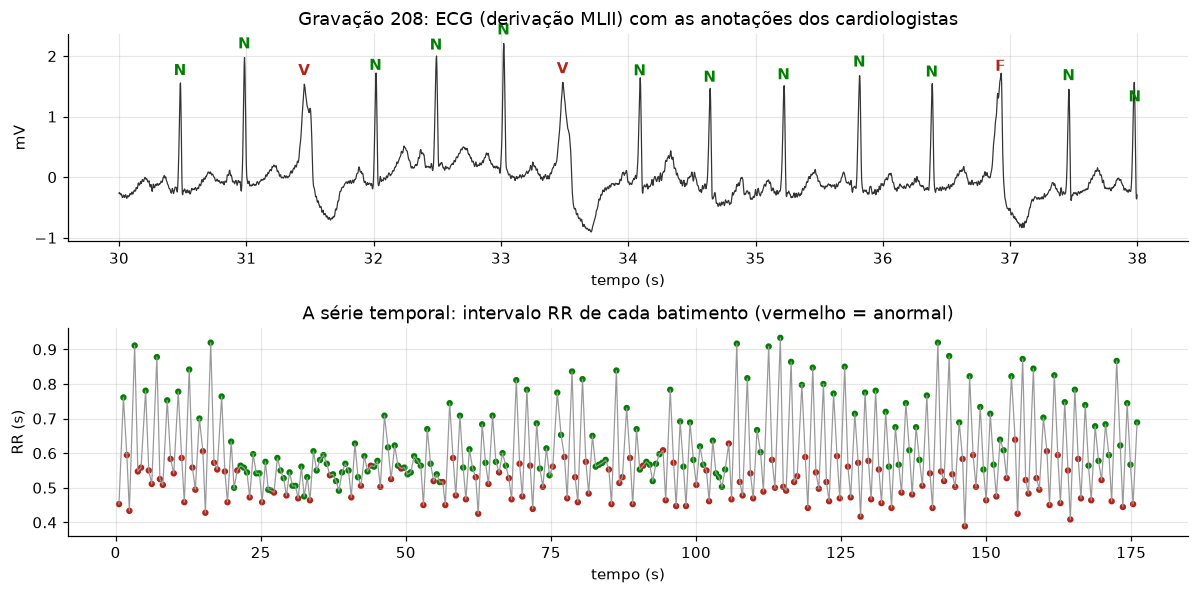

In [3]:
reg = wfdb.rdrecord(str(PASTA / "208"))
ann = wfdb.rdann(str(PASTA / "208"), "atr")
mlii = reg.p_signal[:, reg.sig_name.index("MLII")]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5.5))
ini, fim = 30 * FS, 38 * FS
t = np.arange(ini, fim) / FS
ax1.plot(t, mlii[ini:fim], color="0.2", lw=0.8)
for s, sy in zip(ann.sample, ann.symbol):
    if ini <= s < fim and sy in AAMI:
        ax1.annotate(sy, (s / FS, mlii[s]), xytext=(0, 6), textcoords="offset points",
                     ha="center", color=COR_B if AAMI[sy] else "green", weight="bold")
ax1.set(title="Gravação 208: ECG (derivação MLII) com as anotações dos cardiologistas",
        xlabel="tempo (s)", ylabel="mV")

picos = np.array([s for s, sy in zip(ann.sample, ann.symbol) if sy in AAMI])
rotulos = np.array([AAMI[sy] for sy in ann.symbol if sy in AAMI])
rr = np.diff(picos) / FS
janela = slice(0, 300)
ax2.plot(picos[1:][janela] / FS, rr[janela], color="0.6", lw=0.8)
ax2.scatter(picos[1:][janela] / FS, rr[janela], c=np.where(rotulos[1:][janela], COR_B, "green"), s=10)
ax2.set(title="A série temporal: intervalo RR de cada batimento (vermelho = anormal)",
        xlabel="tempo (s)", ylabel="RR (s)")
plt.tight_layout(); plt.show()

## 2. Pré-processamento

Para cada batimento anotado:

1. **Filtro passa-faixa 0,5–40 Hz** (Butterworth, ida e volta para não deslocar
   a onda): remove a oscilação lenta da linha de base (respiração) e o ruído da
   rede elétrica.
2. **Normalização por gravação** (mediana e desvio-padrão), para que eletrodos
   e pacientes diferentes fiquem na mesma escala.
3. **Janela da onda:** de 0,25 s antes a 0,40 s depois do pico R, reamostrada
   para 180 Hz → **117 amostras**.
4. **Atributos de ritmo (5):** RR anterior, RR seguinte, RR médio dos últimos
   10 batimentos, e as razões RR anterior / RR médio e RR seguinte / RR anterior.
   As razões tornam o atributo **relativo ao próprio paciente**: 0,6 s é
   prematuro para quem bate a 60 BPM, mas normal para quem bate a 100.

Os dois modelos recebem os mesmos 117 + 5 números.

In [4]:
b, a = butter(2, [0.5 / (FS / 2), 40 / (FS / 2)], btype="band")
ANTES, DEPOIS = 90, 144   # amostras a 360 Hz (0,25 s e 0,40 s)


def carregar(gravacoes):
    ondas, ritmo, classes, origem = [], [], [], []
    for r in gravacoes:
        reg = wfdb.rdrecord(str(PASTA / str(r)))
        ann = wfdb.rdann(str(PASTA / str(r)), "atr")
        sinal = filtfilt(b, a, reg.p_signal[:, reg.sig_name.index("MLII")])
        sinal = (sinal - np.median(sinal)) / np.std(sinal)
        # todos os batimentos (inclusive os não classificáveis) entram no cálculo do RR
        batidas = [(s, sy) for s, sy in zip(ann.sample, ann.symbol) if sy in AAMI or sy in "/fQ"]
        rr = np.diff([s for s, _ in batidas]) / FS
        for i in range(1, len(batidas) - 1):
            s, sy = batidas[i]
            if sy not in AAMI or s < ANTES or s + DEPOIS > len(sinal):
                continue
            rr_medio = rr[max(0, i - 10):i].mean()
            ondas.append(sinal[s - ANTES:s + DEPOIS:2])
            ritmo.append([rr[i - 1], rr[i], rr_medio, rr[i - 1] / rr_medio, rr[i] / rr[i - 1]])
            classes.append(AAMI[sy])
            origem.append(r)
    return (np.array(ondas, np.float32), np.array(ritmo, np.float32),
            np.array(classes), np.array(origem))


onda_tr, rr_tr, y_tr, grav_tr = carregar(DS1)
onda_te, rr_te, y_te, grav_te = carregar(DS2)

# atributos de ritmo padronizados com a média e o desvio do TREINO
media_rr, desvio_rr = rr_tr.mean(0), rr_tr.std(0)
rr_tr = (rr_tr - media_rr) / desvio_rr
rr_te = (rr_te - media_rr) / desvio_rr

pd.DataFrame({
    "batimentos": [len(y_tr), len(y_te)],
    "normais": [(y_tr == 0).sum(), (y_te == 0).sum()],
    "anormais": [(y_tr == 1).sum(), (y_te == 1).sum()],
    "% anormal": [f"{y_tr.mean():.1%}", f"{y_te.mean():.1%}"],
}, index=["treino (DS1)", "teste (DS2)"])

,batimentos,normais,anormais,% anormal
treino (DS1),50969,45824,5145,10.1%
teste (DS2),49661,44218,5443,11.0%


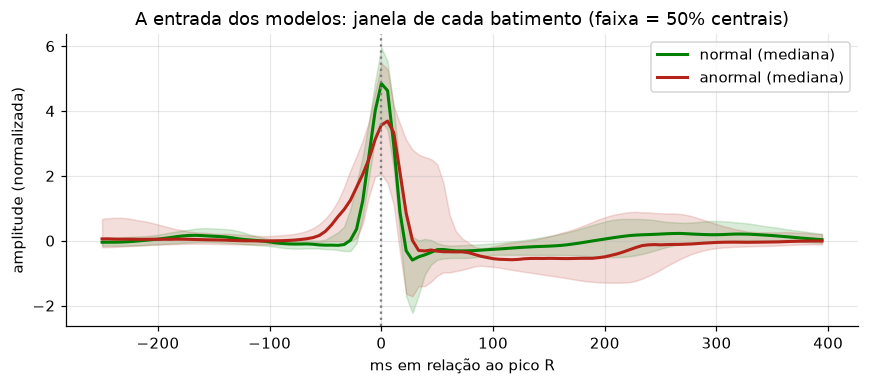

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
tempo_janela = (np.arange(117) * 2 - ANTES) / FS * 1000
for classe, cor, nome in [(0, "green", "normal"), (1, COR_B, "anormal")]:
    amostra = onda_tr[y_tr == classe]
    ax.plot(tempo_janela, np.median(amostra, 0), color=cor, lw=2, label=f"{nome} (mediana)")
    ax.fill_between(tempo_janela, *np.percentile(amostra, [25, 75], 0), color=cor, alpha=0.15)
ax.axvline(0, color="0.5", ls=":")
ax.set(xlabel="ms em relação ao pico R", ylabel="amplitude (normalizada)",
       title="A entrada dos modelos: janela de cada batimento (faixa = 50% centrais)")
ax.legend(); plt.tight_layout(); plt.show()

**Desbalanceamento:** só ~10% dos batimentos são anormais. Um modelo que diz
sempre "normal" acerta 90% e não serve para nada. Por isso:

- os dois modelos são treinados com **peso maior para a classe rara**
  (`class_weight="balanced"`);
- a métrica principal é a **acurácia balanceada** (média entre sensibilidade e
  especificidade), e olhamos também **sensibilidade** (quantas arritmias o
  modelo pega), **precisão** (dos alarmes, quantos são reais) e **AUC**.

Hiperparâmetros são escolhidos por **validação cruzada agrupada por paciente
dentro do DS1** (`GroupKFold`). O DS2 só é usado uma vez, no final.

In [6]:
def metricas(y, pred, escore):
    return {
        "acurácia balanceada": balanced_accuracy_score(y, pred),
        "sensibilidade": recall_score(y, pred),
        "especificidade": recall_score(y, pred, pos_label=0),
        "precisão": precision_score(y, pred),
        "F1": f1_score(y, pred),
        "AUC": roc_auc_score(y, escore),
    }


def regressao_logistica(C):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, class_weight="balanced", max_iter=3000))


def validacao_cruzada(X, C):
    # 3 dobras, cada uma com pacientes que o modelo não viu no treino
    notas = []
    for i_tr, i_va in GroupKFold(n_splits=3).split(X, y_tr, grav_tr):
        modelo = regressao_logistica(C).fit(X[i_tr], y_tr[i_tr])
        notas.append(balanced_accuracy_score(y_tr[i_va], modelo.predict(X[i_va])))
    return np.mean(notas)

## 3. Modelo A: regressão logística

$$P(\text{anormal}) = \sigma(w \cdot x + b) = \frac{1}{1 + e^{-(w \cdot x + b)}}$$

Um peso por entrada (122 + 1 parâmetros). Treina em segundos, é interpretável
(o peso diz quanto cada amostra da onda ou cada atributo de ritmo empurra para
"anormal") e é linear: só separa o que uma reta (um hiperplano) separa.

In [7]:
X_tr = np.hstack([onda_tr, rr_tr])
X_te = np.hstack([onda_te, rr_te])

notas_c = {C: validacao_cruzada(X_tr, C) for C in [0.01, 0.1, 1.0]}
for C, nota in notas_c.items():
    print(f"C = {C:<5} acurácia balanceada na validação (DS1): {nota:.3f}")
C_A = max(notas_c, key=notas_c.get)
print("escolhido: C =", C_A)

C = 0.01  acurácia balanceada na validação (DS1): 0.764
C = 0.1   acurácia balanceada na validação (DS1): 0.780
C = 1.0   acurácia balanceada na validação (DS1): 0.783
escolhido: C = 1.0


In [8]:
inicio = time.perf_counter()
modelo_a = regressao_logistica(C_A).fit(X_tr, y_tr)
treino_a = time.perf_counter() - inicio

inicio = time.perf_counter()
escore_a = modelo_a.decision_function(X_te)
inferencia_a = (time.perf_counter() - inicio) / len(X_te)
pred_a = (escore_a > 0).astype(int)
resultado_a = metricas(y_te, pred_a, escore_a)
pd.Series(resultado_a).round(3).to_frame("Regressão logística (teste DS2)")

,Regressão logística (teste DS2)
acurácia balanceada,0.898
sensibilidade,0.908
especificidade,0.889
precisão,0.502
F1,0.646
AUC,0.960


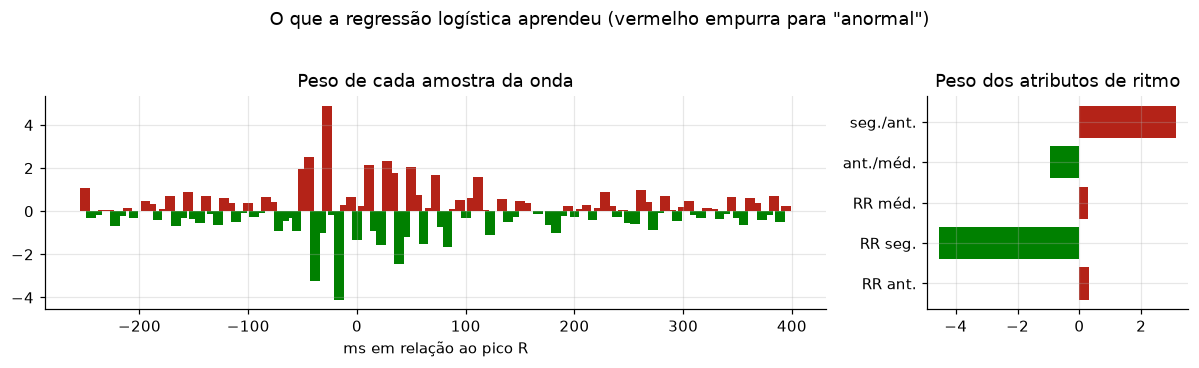

In [9]:
pesos = modelo_a[-1].coef_[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [3, 1]})
ax1.bar(tempo_janela, pesos[:117], width=9, color=np.where(pesos[:117] > 0, COR_B, "green"))
ax1.set(title="Peso de cada amostra da onda", xlabel="ms em relação ao pico R")
nomes_rr = ["RR ant.", "RR seg.", "RR méd.", "ant./méd.", "seg./ant."]
ax2.barh(nomes_rr, pesos[117:], color=np.where(pesos[117:] > 0, COR_B, "green"))
ax2.set(title="Peso dos atributos de ritmo")
plt.suptitle("O que a regressão logística aprendeu (vermelho empurra para \"anormal\")", y=1.03)
plt.tight_layout(); plt.show()

Os maiores pesos estão no **ritmo**: um RR anterior curto em relação à média
(batimento prematuro) e uma pausa longa depois são a assinatura das
extrassístoles. Na onda, o modelo olha a região do QRS e da onda T, onde os
batimentos ventriculares ficam largos e deformados.

## 4. Modelo B: rede neuromórfica com neurônios LIF

### O neurônio Leaky Integrate-and-Fire

Cada neurônio tem um **potencial de membrana** $v$ que:

- **integra** a corrente de entrada $I(t)$;
- **vaza** de volta para o repouso com constante de tempo $\tau_m$ (o "leaky");
- ao cruzar o **limiar** $v_{th}$, **dispara um spike** e volta para $v_{reset}$.

$$\tau_m \frac{dv}{dt} = -v + R\,I(t) \qquad \text{se } v \ge v_{th}: \text{ spike e } v \leftarrow v_{reset}$$

Discretizando com o passo do sinal ($\Delta t = 1/180$ s), a atualização a cada
amostra é:

$$v_{t+1} = \beta\, v_t + (1 - \beta)\, R\, I_t, \qquad \beta = e^{-\Delta t / \tau_m}$$

Usamos $\tau_m = 20$ ms, $v_{th} = 1$ e $v_{reset} = 0$. A informação está
**em quando e quantas vezes** o neurônio dispara, não num número contínuo.

### A rede

É uma **reservatório de spikes** (*Liquid State Machine*, Maass et al., 2002),
a forma mais simples e mais usada de rede neuromórfica:

1. **Codificação:** a onda entra amostra por amostra, separada em dois canais,
   **ON** (parte positiva) e **OFF** (parte negativa), como as células da
   retina. Os 5 atributos de ritmo entram como **correntes constantes**: quanto
   maior o valor, mais rápido o neurônio dispara (codificação por taxa).
2. **300 neurônios LIF** com pesos de entrada aleatórios e **conexões
   recorrentes** esparsas (10%): um spike de um neurônio injeta corrente nos
   vizinhos. A recorrência dá memória: a rede "lembra" o começo do batimento
   quando chega o fim.
3. **Leitura:** contamos os spikes de cada neurônio em 4 fatias de tempo da
   janela (300 × 4 = 1.200 contagens) e uma regressão logística decide.

Os pesos dos neurônios são **fixos e aleatórios**: só a leitura é treinada.
É assim que muitos chips neuromórficos aprendem no próprio hardware, porque
treinar a rede inteira exigiria retropropagar através dos spikes, que não são
deriváveis.

In [10]:
class RedeLIF:
    # Reservatório de 300 neurônios LIF simulado em lote (todos os batimentos juntos).

    def __init__(self, n=300, tau_m=0.020, dt=1 / 180, ganho_entrada=1.0, ganho_ritmo=0.5,
                 escala=2.0, recorrencia=0.2, densidade=0.1, fatias=4, semente=SEMENTE):
        aleatorio = np.random.default_rng(semente)
        self.n, self.fatias, self.escala = n, fatias, escala
        self.beta = np.exp(-dt / tau_m)                                     # vazamento por passo
        self.w_onda = aleatorio.normal(0, ganho_entrada, (2, n)).astype(np.float32)   # canais ON/OFF
        self.w_ritmo = aleatorio.normal(0, ganho_ritmo, (5, n)).astype(np.float32)
        self.vies = aleatorio.uniform(-0.5, 0.5, n).astype(np.float32)        # excitabilidade de cada neurônio
        conexoes = aleatorio.random((n, n)) < densidade
        w = aleatorio.normal(0, 1, (n, n)) * conexoes * recorrencia / np.sqrt(densidade * n)
        self.w_rec = w.astype(np.float32)
        self.sinapses = int(conexoes.sum())

    def simular(self, onda, ritmo, gravar=False):
        lote, passos = onda.shape
        v = np.zeros((lote, self.n), np.float32)
        spikes = np.zeros_like(v)
        contagens = np.zeros((lote, self.fatias, self.n), np.float32)
        corrente_ritmo = ritmo @ self.w_ritmo + self.vies          # constante durante o batimento
        canais = np.stack([np.clip(onda, 0, None), np.clip(-onda, 0, None)], axis=2)  # ON / OFF
        historico_v, historico_s = [], []
        for t in range(passos):
            corrente = canais[:, t] @ self.w_onda + corrente_ritmo + spikes @ self.w_rec
            v = self.beta * v + (1 - self.beta) * self.escala * corrente   # integra e vaza
            spikes = (v >= 1.0).astype(np.float32)                         # dispara no limiar
            v = np.where(spikes > 0, 0.0, v)                               # reset
            if gravar:
                historico_v.append(v.copy()); historico_s.append(spikes.copy())
            contagens[:, t * self.fatias // passos] += spikes
        atributos = contagens.reshape(lote, -1)
        if gravar:
            return atributos, np.stack(historico_v, 1), np.stack(historico_s, 1)
        return atributos

### Um neurônio por dentro

Abaixo, o mesmo neurônio recebendo um batimento normal e um ventricular. O
potencial sobe com a corrente, vaza, e a cada cruzamento do limiar gera um
spike (traço preto) e volta a zero. Embaixo, o *raster* da rede inteira: cada
ponto é um spike. No batimento prematuro, os atributos de ritmo fora do comum
viram correntes fortes e a rede inteira dispara muito mais: é assim que o
"chegou cedo" aparece para a leitura.

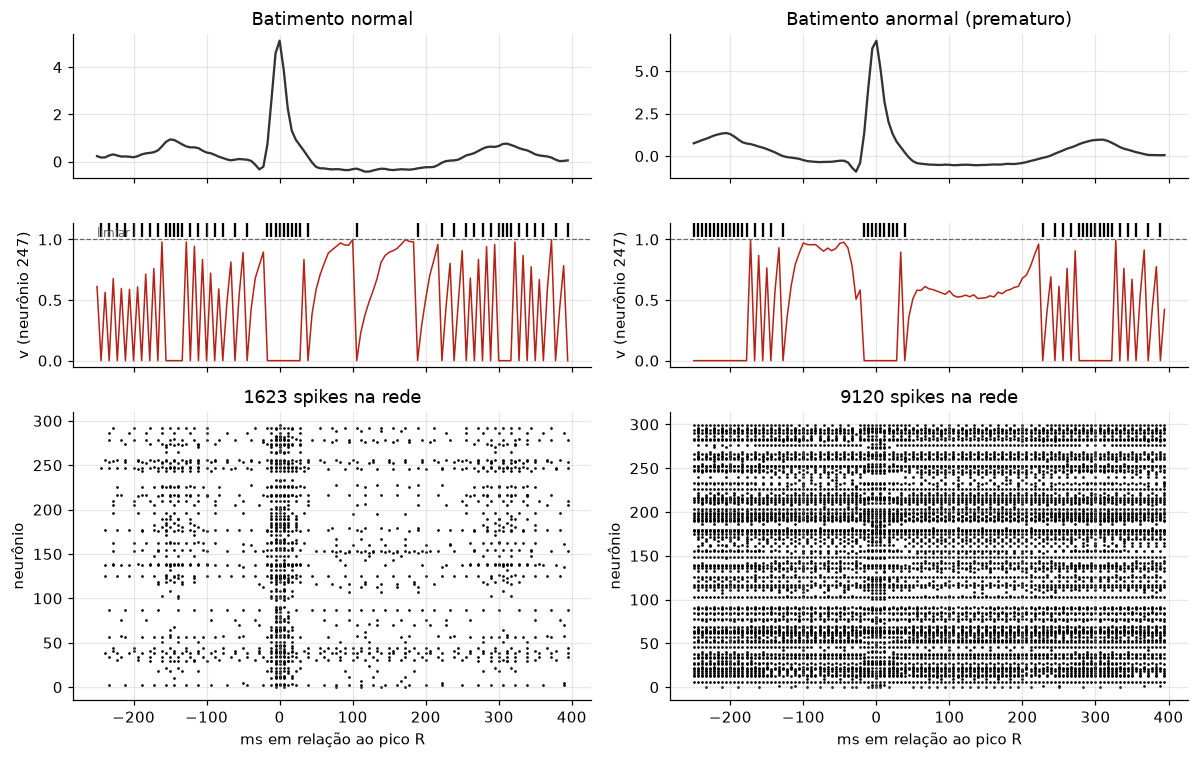

In [11]:
rede = RedeLIF()
i_normal = np.where(y_tr == 0)[0][100]
i_anormal = np.where((y_tr == 1) & (rr_tr[:, 3] < -1.5))[0][0]   # um batimento prematuro
_, v_hist, s_hist = rede.simular(onda_tr[[i_normal, i_anormal]], rr_tr[[i_normal, i_anormal]], gravar=True)

neuronio = int(np.argmax(s_hist[0].sum(0) * (s_hist[1].sum(0) != s_hist[0].sum(0))))
fig, eixos = plt.subplots(3, 2, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1, 2]})
for col, (i, nome) in enumerate([(i_normal, "normal"), (i_anormal, "anormal (prematuro)")]):
    eixos[0, col].plot(tempo_janela, onda_tr[i], color="0.2")
    eixos[0, col].set_title(f"Batimento {nome}")
    eixos[1, col].plot(tempo_janela, v_hist[col][:, neuronio], color=COR_B, lw=1)
    eixos[1, col].axhline(1, color="0.4", ls="--", lw=0.8)
    picos_spk = np.where(s_hist[col][:, neuronio])[0]
    eixos[1, col].scatter(tempo_janela[picos_spk], np.full(len(picos_spk), 1.08), marker="|", s=80, color="k")
    eixos[1, col].set_ylabel(f"v (neurônio {neuronio})")
    tt, nn = np.where(s_hist[col])
    eixos[2, col].scatter(tempo_janela[tt], nn, s=0.6, color="k")
    eixos[2, col].set(ylabel="neurônio", xlabel="ms em relação ao pico R",
                      title=f"{len(tt)} spikes na rede")
eixos[1, 0].text(tempo_janela[0], 1.02, "limiar", color="0.4", fontsize=8)
plt.tight_layout(); plt.show()

### Escolha da escala de entrada e treino da leitura

Ajustamos só a **escala** da corrente (quanto o
neurônio reage à entrada): pouca escala deixa a rede muda, escala demais faz
todo mundo disparar o tempo todo e a informação se perde. Escolhemos pela
validação cruzada por paciente no DS1, como no modelo A. A leitura usa o
mesmo `C` escolhido para o modelo A.

In [12]:
notas_escala = {}
for escala in [1.0, 2.0, 4.0]:
    rede_teste = RedeLIF(escala=escala)
    atributos = rede_teste.simular(onda_tr, rr_tr)
    taxa = atributos.sum(1).mean() / (rede_teste.n * onda_tr.shape[1])
    notas_escala[escala] = validacao_cruzada(atributos, C_A)
    print(f"escala {escala}: {taxa:.1%} dos neurônios disparam por passo · "
          f"acurácia balanceada na validação (DS1): {notas_escala[escala]:.3f}")
ESCALA_B = max(notas_escala, key=notas_escala.get)
print("escolhida: escala =", ESCALA_B)

escala 1.0: 3.5% dos neurônios disparam por passo · acurácia balanceada na validação (DS1): 0.832


escala 2.0: 9.4% dos neurônios disparam por passo · acurácia balanceada na validação (DS1): 0.818


escala 4.0: 18.7% dos neurônios disparam por passo · acurácia balanceada na validação (DS1): 0.841
escolhida: escala = 4.0


In [13]:
rede = RedeLIF(escala=ESCALA_B)

inicio = time.perf_counter()
spk_tr = rede.simular(onda_tr, rr_tr)
modelo_b = regressao_logistica(C_A).fit(spk_tr, y_tr)
treino_b = time.perf_counter() - inicio

inicio = time.perf_counter()
spk_te = rede.simular(onda_te, rr_te)
escore_b = modelo_b.decision_function(spk_te)
inferencia_b = (time.perf_counter() - inicio) / len(spk_te)
pred_b = (escore_b > 0).astype(int)
resultado_b = metricas(y_te, pred_b, escore_b)
spikes_por_batimento = spk_te.sum(1).mean()
pd.Series(resultado_b).round(3).to_frame("Rede LIF (teste DS2)")

,Rede LIF (teste DS2)
acurácia balanceada,0.828
sensibilidade,0.781
especificidade,0.875
precisão,0.435
F1,0.559
AUC,0.897


**Análise de sensibilidade (não usada para escolher nada).** Como a escala
mudaria o resultado no teste? Esta célula só existe para medir quanto a rede
LIF depende desse ajuste; a escolha acima foi feita apenas com a validação.

In [14]:
sensibilidade_escala = {}
for escala in [1.0, 2.0, 4.0]:
    rede_s = RedeLIF(escala=escala)
    leitura = regressao_logistica(C_A).fit(rede_s.simular(onda_tr, rr_tr), y_tr)
    sensibilidade_escala[escala] = balanced_accuracy_score(y_te, leitura.predict(rede_s.simular(onda_te, rr_te)))
pd.Series(sensibilidade_escala, name="acurácia balanceada no teste").rename_axis("escala").round(3).to_frame()

,acurácia balanceada no teste
escala,
1.0,0.832
2.0,0.874
4.0,0.828


## 5. Comparação

### Desempenho no teste (22 pacientes nunca vistos)

In [15]:
tabela = pd.DataFrame({"Regressão logística": resultado_a, "Rede LIF": resultado_b}).round(3)
tabela

,Regressão logística,Rede LIF
acurácia balanceada,0.898,0.828
sensibilidade,0.908,0.781
especificidade,0.889,0.875
precisão,0.502,0.435
F1,0.646,0.559
AUC,0.960,0.897


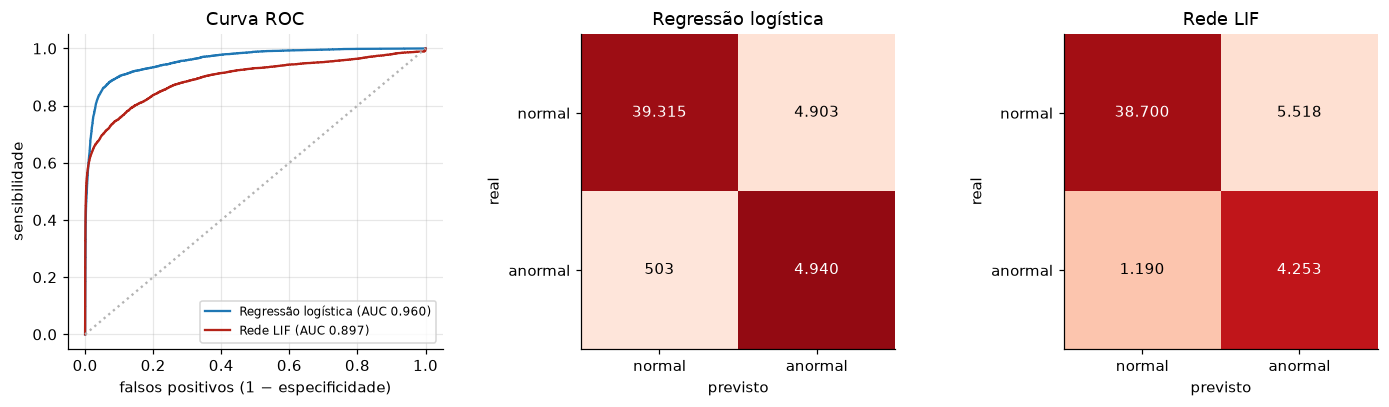

In [16]:
fig, eixos = plt.subplots(1, 3, figsize=(13, 3.8))
for nome, escore, cor in [("Regressão logística", escore_a, COR_A), ("Rede LIF", escore_b, COR_B)]:
    fpr, tpr, _ = roc_curve(y_te, escore)
    eixos[0].plot(fpr, tpr, color=cor, label=f"{nome} (AUC {roc_auc_score(y_te, escore):.3f})")
eixos[0].plot([0, 1], [0, 1], color="0.7", ls=":")
eixos[0].set(xlabel="falsos positivos (1 − especificidade)", ylabel="sensibilidade", title="Curva ROC")
eixos[0].legend(loc="lower right", fontsize=8)
for ax, (nome, pred) in zip(eixos[1:], [("Regressão logística", pred_a), ("Rede LIF", pred_b)]):
    m = confusion_matrix(y_te, pred)
    ax.imshow(m / m.sum(1, keepdims=True), cmap="Reds", vmin=0, vmax=1)
    for (i, j), valor in np.ndenumerate(m):
        ax.text(j, i, f"{valor:,}".replace(",", "."), ha="center", va="center",
                color="white" if m[i, j] / m[i].sum() > 0.5 else "black")
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["normal", "anormal"],
           yticklabels=["normal", "anormal"], xlabel="previsto", ylabel="real", title=nome)
    ax.grid(False)
plt.tight_layout(); plt.show()

### Por tipo de arritmia

A sensibilidade agregada esconde diferenças: batimentos **ventriculares (V)**
são largos e deformados, fáceis de ver na onda; os **supraventriculares (S)**
têm onda quase normal e só se denunciam pelo ritmo (chegam cedo).

In [17]:
def tipos(gravacoes):
    lista = []
    for r in gravacoes:
        reg_len = wfdb.rdheader(str(PASTA / str(r))).sig_len
        ann = wfdb.rdann(str(PASTA / str(r)), "atr")
        batidas = [(s, sy) for s, sy in zip(ann.sample, ann.symbol) if sy in AAMI or sy in "/fQ"]
        for i in range(1, len(batidas) - 1):
            s, sy = batidas[i]
            if sy in AAMI and s >= ANTES and s + DEPOIS <= reg_len:
                lista.append("N" if sy in "NLRej" else "S" if sy in "AaJS" else "V" if sy in "VE" else "F")
    return np.array(lista)


tipo_te = tipos(DS2)
assert len(tipo_te) == len(y_te)
por_tipo = pd.DataFrame({
    nome: {t: (pred[tipo_te == t] == (t != "N")).mean() for t in "NSVF"}
    for nome, pred in [("Regressão logística", pred_a), ("Rede LIF", pred_b)]
})
por_tipo.insert(0, "batimentos", [int((tipo_te == t).sum()) for t in "NSVF"])
por_tipo.index = ["N (acerto = especificidade)", "S supraventricular", "V ventricular", "F fusão"]
por_tipo.round(3)

,batimentos,Regressão logística,Rede LIF
N (acerto = especificidade),44218,0.889,0.875
S supraventricular,1836,0.898,0.526
V ventricular,3219,0.983,0.961
F fusão,388,0.327,0.503


A regressão logística pega quase todas as **S** (supraventriculares): o peso
alto no RR anterior curto, que vimos acima, é exatamente a regra "chegou cedo".
A rede LIF perde metade delas: os atributos de ritmo entram como correntes
misturadas à onda em 300 neurônios aleatórios, e a leitura não recupera essa
regra simples com a mesma nitidez. Nos batimentos de **fusão (F)**, uma mistura
de batimento normal com ventricular, a LIF acerta mais: é onde uma combinação
não linear da forma da onda ajuda.

### Custo computacional

Contamos as operações por batimento. Uma **MAC** é uma multiplicação seguida
de soma (o que a CPU e a GPU fazem). Num chip neuromórfico, um spike que chega
a uma sinapse gera só uma **soma** (AC), e só quando há spike: o custo é
proporcional à atividade, não ao tamanho da rede.

In [18]:
passos = onda_te.shape[1]
macs_a = X_te.shape[1]
macs_b_entrada = passos * 2 * rede.n + 5 * rede.n             # injeção da onda e do ritmo
acs_b_recorrentes = spikes_por_batimento * (rede.sinapses / rede.n)   # cada spike × sinapses de saída
macs_b_leitura = spk_te.shape[1]

custo = pd.DataFrame({
    "Regressão logística": {
        "parâmetros treinados": macs_a + 1,
        "parâmetros fixos (aleatórios)": 0,
        "MACs por batimento": macs_a,
        "somas por spike (AC) por batimento": 0,
        "spikes por batimento": 0,
        "tempo de treino (s)": round(treino_a, 2),
        "inferência por batimento (µs, CPU)": round(inferencia_a * 1e6, 2),
    },
    "Rede LIF": {
        "parâmetros treinados": macs_b_leitura + 1,
        "parâmetros fixos (aleatórios)": rede.w_onda.size + rede.w_ritmo.size + rede.n + rede.sinapses,
        "MACs por batimento": macs_b_entrada + macs_b_leitura,
        "somas por spike (AC) por batimento": int(acs_b_recorrentes),
        "spikes por batimento": int(spikes_por_batimento),
        "tempo de treino (s)": round(treino_b, 2),
        "inferência por batimento (µs, CPU)": round(inferencia_b * 1e6, 2),
    },
})
custo

,Regressão logística,Rede LIF
parâmetros treinados,123.00,1201.00
parâmetros fixos (aleatórios),0.00,11293.00
MACs por batimento,122.00,72900.00
somas por spike (AC) por batimento,0.00,208971.00
spikes por batimento,0.00,7049.00
tempo de treino (s),0.65,9.72
"inferência por batimento (µs, CPU)",0.11,117.93


### Robustez a ruído

Um vestível capta ruído de movimento e de contato do eletrodo. Adicionamos
ruído gaussiano **só na onda do teste** (os modelos foram treinados com sinal
limpo) e medimos quanto cada modelo perde. O desvio do ruído é relativo ao
desvio do próprio sinal (σ = 0,5 é ruído com metade da "força" do ECG).

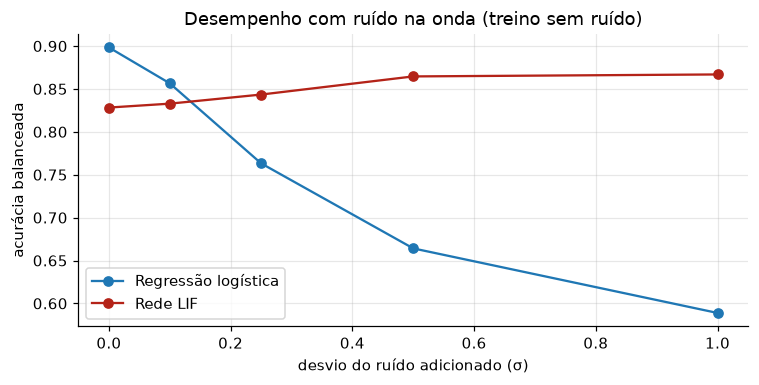

acurácia balanceada                          AUC         
         Regressão logística Rede LIF Regressão logística Rede LIF
σ = 0.0                0.898    0.828               0.960    0.897
σ = 0.1                0.857    0.833               0.938    0.900
σ = 0.25               0.763    0.843               0.851    0.909
σ = 0.5                0.664    0.865               0.731    0.926
σ = 1.0                0.589    0.867               0.628    0.943

In [19]:
aleatorio = np.random.default_rng(SEMENTE)
niveis = [0.0, 0.1, 0.25, 0.5, 1.0]
robustez = {"Regressão logística": [], "Rede LIF": []}
auc_ruido = {"Regressão logística": [], "Rede LIF": []}
for sigma in niveis:
    ruidosa = onda_te + aleatorio.normal(0, sigma, onda_te.shape).astype(np.float32)
    for nome, escore in [("Regressão logística", modelo_a.decision_function(np.hstack([ruidosa, rr_te]))),
                         ("Rede LIF", modelo_b.decision_function(rede.simular(ruidosa, rr_te)))]:
        robustez[nome].append(balanced_accuracy_score(y_te, (escore > 0).astype(int)))
        auc_ruido[nome].append(roc_auc_score(y_te, escore))

fig, ax = plt.subplots(figsize=(7, 3.6))
for nome, cor in [("Regressão logística", COR_A), ("Rede LIF", COR_B)]:
    ax.plot(niveis, robustez[nome], "o-", color=cor, label=nome)
ax.set(xlabel="desvio do ruído adicionado (σ)", ylabel="acurácia balanceada",
       title="Desempenho com ruído na onda (treino sem ruído)")
ax.legend(); plt.tight_layout(); plt.show()
pd.concat({"acurácia balanceada": pd.DataFrame(robustez, index=[f"σ = {s}" for s in niveis]),
           "AUC": pd.DataFrame(auc_ruido, index=[f"σ = {s}" for s in niveis])}, axis=1).round(3)

Aqui a diferença é grande. A **regressão logística desaba**: o ruído entra
linearmente na soma ponderada, e com σ = 1 ela fica perto do chute (0,5). A
**rede LIF não perde nada**, e chega a melhorar. Duas razões:

- **O neurônio filtra.** O potencial de membrana integra a entrada com
  τ = 20 ms (≈ 4 amostras), o que funciona como um filtro passa-baixa natural,
  e o limiar descarta flutuações pequenas.
- **A rede passa a se apoiar no ritmo.** O ruído aleatório, retificado nos
  canais ON e OFF, vira quase uma excitação constante: a forma da onda some e
  sobra a informação dos intervalos RR, que (próxima célula) sozinha já dá
  0,86 na LIF. A melhora, portanto, não é "o ruído ajuda": é a rede trocando
  uma informação que generaliza mal entre pacientes (a forma exata da onda)
  por outra que generaliza bem (o ritmo).

### Uma verificação: quanto vem do ritmo?

Treinamos os dois modelos de novo com só uma parte da entrada: só a onda, ou
só os 5 atributos de ritmo. Isso mostra de onde vem a informação.

In [20]:
zeros_rr_tr, zeros_rr_te = np.zeros_like(rr_tr), np.zeros_like(rr_te)        # sem corrente de ritmo
zeros_onda_tr, zeros_onda_te = np.zeros_like(onda_tr), np.zeros_like(onda_te)  # sem onda


def acuracia_a(entrada_tr, entrada_te):
    return balanced_accuracy_score(y_te, regressao_logistica(C_A).fit(entrada_tr, y_tr).predict(entrada_te))


def acuracia_b(onda_treino, rr_treino, onda_teste, rr_teste):
    leitura = regressao_logistica(C_A).fit(rede.simular(onda_treino, rr_treino), y_tr)
    return balanced_accuracy_score(y_te, leitura.predict(rede.simular(onda_teste, rr_teste)))


pd.DataFrame({
    "onda + ritmo": [resultado_a["acurácia balanceada"], resultado_b["acurácia balanceada"]],
    "só a onda": [acuracia_a(onda_tr, onda_te), acuracia_b(onda_tr, zeros_rr_tr, onda_te, zeros_rr_te)],
    "só o ritmo": [acuracia_a(rr_tr, rr_te), acuracia_b(zeros_onda_tr, rr_tr, zeros_onda_te, rr_te)],
}, index=["Regressão logística", "Rede LIF"]).round(3)

,onda + ritmo,só a onda,só o ritmo
Regressão logística,0.898,0.709,0.892
Rede LIF,0.828,0.740,0.862


## 6. Conclusões

In [21]:
# Números usados no texto abaixo e no relatório
resumo = pd.concat([tabela.T, custo.T[["MACs por batimento", "spikes por batimento",
                                       "tempo de treino (s)", "inferência por batimento (µs, CPU)"]]], axis=1)
resumo.T

,Regressão logística,Rede LIF
acurácia balanceada,0.898,0.828
sensibilidade,0.908,0.781
especificidade,0.889,0.875
precisão,0.502,0.435
F1,0.646,0.559
AUC,0.960,0.897
MACs por batimento,122.000,72900.000
spikes por batimento,0.000,7049.000
tempo de treino (s),0.650,9.720
"inferência por batimento (µs, CPU)",0.110,117.930


**Desempenho com sinal limpo: vitória da regressão logística.** Com a mesma
entrada e os hiperparâmetros escolhidos só na validação, ela fez **0,898** de
acurácia balanceada e **0,960** de AUC, contra **0,828** e **0,897** da rede LIF.
A diferença vem quase toda das arritmias supraventriculares, que dependem de
uma regra linear simples sobre o ritmo ("chegou cedo"), que a regressão
logística acha diretamente. O ritmo é a parte mais valiosa da série temporal:
sozinho, ele dá 0,892 para a regressão logística; a onda sozinha dá 0,71–0,74.

**Onde a rede LIF tem vantagem:**

- **Robustez a ruído.** Com ruído forte na onda, a regressão logística cai
  para perto do chute e a LIF se mantém (0,867 com σ = 1). Para um vestível,
  que capta movimento e mau contato do eletrodo, isso pesa muito.
- **Formas não lineares:** com só a onda, a LIF supera a regressão logística
  (0,740 × 0,709) e acerta mais os batimentos de fusão.
- **Processa em fluxo.** Ela consome o sinal amostra por amostra, com memória
  no potencial de membrana e nas conexões recorrentes; num vestível, poderia
  rodar continuamente sobre o ECG.
- **Custo proporcional à atividade em hardware neuromórfico** (Intel Loihi,
  SpiNNaker, BrainChip Akida): neurônio sem spike não gasta energia e cada
  spike custa uma soma. É o caminho para monitorar 24 h com pouca bateria.
- **Aprendizado só na leitura:** trocar de paciente ou de tarefa exige treinar
  apenas a última camada, algo viável no próprio dispositivo.

**Limitações da rede LIF, medidas aqui:**

- **Numa CPU comum ela é muito mais cara:** ~73 mil multiplicações e ~200 mil
  somas por batimento, contra 122 multiplicações da regressão logística, e
  inferência ~1.000 vezes mais lenta (≈ 120 µs × 0,1 µs). A vantagem de
  energia só existe em hardware neuromórfico, que não usamos.
- **Sensível a hiperparâmetros:** a escala escolhida pela validação (4,0) deu
  0,828 no teste, mas a escala 2,0 daria 0,874. Com só 22 pacientes de treino,
  a validação não consegue separar diferenças desse tamanho.
- **Menos interpretável:** os pesos da regressão logística mostram o que
  importa; as contagens de spikes de neurônios aleatórios não.
- **Treino limitado:** sem retropropagação pelos spikes, só a leitura aprende.
  Redes treinadas de ponta a ponta com *gradiente substituto* costumam fechar
  a diferença, ao custo de mais complexidade.

**Para o CardioIA:** hoje, no ESP32 do vestível, a **regressão logística com
atributos de ritmo** é a escolha certa: barata, rápida, explicável e a melhor
com sinal limpo, desde que o sinal passe por um filtro e por um controle de
qualidade (descartar trechos ruidosos). A rede LIF passa a fazer sentido
quando o ruído for inevitável ou quando houver um coprocessador neuromórfico
para monitorar o tempo todo com pouca energia.

**Cuidados metodológicos** que tornam os números honestos: treino e teste com
pacientes diferentes, hiperparâmetros escolhidos só no treino, métricas para
dados desbalanceados e a mesma entrada para os dois modelos.